# Actividad 5: Pipeline de scikit-learn con MLflow

Este notebook adapta el pipeline de predicción de demanda y separa el trabajo en etapas.
Usa **Experiments**, **Tracking**, **Models** y, de forma opcional, **Model Registry**.
Los datos son sintéticos; no se necesita un Feature Store para esta actividad.

Ejecuta las celdas en orden con el entorno de esta actividad. Desde esta carpeta:
```bash
uv sync --extra notebook
uv run --extra notebook jupyter lab pipeline_mlflow.ipynb
```

`src/data.py` contiene la generación de datos y `src/pipeline.py` conserva los
transformadores y funciones reutilizables. Aquí se muestra explícitamente la
integración con MLflow, sin ocultarla en una sola llamada al pipeline.


## 1. Importaciones y ubicación del proyecto

Se admite abrir Jupyter desde la carpeta de la actividad, desde `src/` o desde
la raíz del repositorio. No se instalan paquetes desde las celdas.


In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import mlflow
import mlflow.sklearn
from IPython.display import display
from mlflow.models import infer_signature
from mlflow.tracking import MlflowClient

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents]
candidates += [p / "workshop/activity-05-databricks-mlflow" for p in list(candidates)]
PROJECT_DIR = next(
    (p for p in candidates if (p / "src/pipeline.py").is_file()), None
)
if PROJECT_DIR is None:
    raise FileNotFoundError("Abre Jupyter dentro del repositorio de esta actividad.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.data import generate_demand_dataset
from src.pipeline import (
    build_pipeline,
    compute_metrics,
    create_evaluation_figure,
    load_env_file,
    split_temporal_data,
)

print(f"Proyecto: {PROJECT_DIR.name} | MLflow: {mlflow.__version__}")


2026/10/16 12:54:49 INFO mlflow.agent.hint: Load the `instrumenting-with-mlflow-tracing` skill at /home/donmathiuz/ml-engineering-portfolio/workshop/activity-05-databricks-mlflow/.venv/lib/python3.12/site-packages/mlflow/assistant/skills/instrumenting-with-mlflow-tracing/SKILL.md before writing any tracing code; it ships with this MLflow install. Set MLFLOW_DISABLE_AGENT_HINT=1 to silence this.


Proyecto: activity-05-databricks-mlflow | MLflow: 3.17.1


## 2. Configurar Experiments

Por defecto se usa SQLite local. Aunque haya credenciales de Databricks en `.env`,
solo se envían datos a Databricks al cambiar `USE_DATABRICKS = True`.
Para ese modo, configura las credenciales fuera del notebook y define
`MLFLOW_EXPERIMENT_NAME` con una ruta de experimento de tu workspace
(por ejemplo, `/Users/tu_usuario/activity-05-demand-pipeline`).

`MLFLOW_TRACKING_URI` permite elegir otro backend local o un servidor MLflow.
Cada ejecución completa del notebook crea un run nuevo en el mismo experimento.


In [2]:
USE_DATABRICKS = False
N_ROWS = 3000
SEED = 42
TEST_SIZE = 0.2
ALPHA = 1.0

load_env_file()
if USE_DATABRICKS:
    tracking_uri = "databricks"
    experiment_name = os.getenv("MLFLOW_EXPERIMENT_NAME")
    if not experiment_name or not experiment_name.startswith("/"):
        raise ValueError("Define MLFLOW_EXPERIMENT_NAME con una ruta de Databricks.")
else:
    tracking_uri = os.getenv("MLFLOW_TRACKING_URI", f"sqlite:///{PROJECT_DIR / 'mlflow.db'}")
    experiment_name = "activity-05-demand-notebook"

mlflow.set_tracking_uri(tracking_uri)
# El registro usa el mismo backend, salvo en Databricks (configuración explícita al final).
if not USE_DATABRICKS:
    mlflow.set_registry_uri(tracking_uri)
experiment = mlflow.set_experiment(experiment_name)
print(f"Experimento: {experiment.name} | ID: {experiment.experiment_id}")


2026/10/16 12:54:51 INFO mlflow.store.db.utils: Creating initial MLflow database tables...


2026/10/16 12:54:51 INFO mlflow.store.db.utils: Updating database tables


2026/10/16 12:54:54 INFO mlflow.tracking.fluent: Experiment with name 'activity-05-demand-notebook' does not exist. Creating a new experiment.


Experimento: activity-05-demand-notebook | ID: 1


## 3. Generar y explorar los datos

La variable objetivo es `demand`. `previous_days_demand` contiene la demanda del
día anterior y se obtiene con `shift(1)`. El generador elimina los días iniciales
sin historial. La semilla permite reproducir los datos.


In [3]:
df = generate_demand_dataset(n_rows=N_ROWS, seed=SEED)
assert df["date"].is_monotonic_increasing
assert not df.isna().any().any()
display(df.head())
display(df.describe())


,date,average_temperature,rainfall,weekend,holiday,price_per_kg,promo,previous_days_demand,competitor_price_per_kg,marketing_intensity,demand
0,2017-10-15,29.651608,0.636457,1,0,1.463572,1,1537.659371,2.430705,0.506294,1573.902381
1,2017-10-16,13.202841,10.093105,0,0,2.734948,1,1573.902381,0.992571,0.590159,1054.471991
2,2017-10-17,21.259648,15.581348,0,0,0.944485,1,1054.471991,1.854718,0.659477,1243.102173
3,2017-10-18,19.269951,0.360803,0,0,2.064598,1,1243.102173,0.591464,0.620754,1063.264052
4,2017-10-19,33.169125,0.473797,0,0,0.499609,1,1063.264052,2.744125,0.555335,1212.264319


,date,average_temperature,rainfall,weekend,holiday,price_per_kg,promo,previous_days_demand,competitor_price_per_kg,marketing_intensity,demand
count,3000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000,3000.000000
mean,2021-11-22 12:00:00,22.481749,4.804136,0.285667,0.030667,1.752326,0.304333,1199.109667,1.758580,0.529357,1198.950293
min,2017-10-15 00:00:00,10.012969,0.003358,0.000000,0.000000,0.250033,0.000000,670.449335,0.500312,0.062653,670.449335
25%,2019-11-03 18:00:00,16.113040,1.348364,0.000000,0.000000,1.129842,0.000000,1018.596282,1.137090,0.424252,1018.596282
50%,2021-11-22 12:00:00,22.398673,3.392996,0.000000,0.000000,1.767125,0.000000,1174.540453,1.769516,0.534585,1174.407864
75%,2023-12-12 06:00:00,28.884563,6.462778,1.000000,0.000000,2.375667,1.000000,1354.256442,2.377295,0.637751,1354.099941
max,2025-12-31 00:00:00,34.994133,41.856218,1.000000,1.000000,3.247635,1.000000,2147.446906,2.999868,0.943279,2147.446906
std,NaN,7.250678,4.910995,0.451807,0.172442,0.742173,0.460201,236.052204,0.714249,0.149107,235.984947


## 4. Separar entrenamiento y prueba

Se reserva el último 20 % para prueba, sin mezclar fechas. Las transformaciones
se ajustarán exclusivamente con entrenamiento. Esta evaluación simula predicciones
diarias con la demanda real del día anterior disponible; para pronosticar varios
días hacia adelante se necesitaría construir ese historial de manera recursiva.
El conjunto de prueba no se usa para elegir `alpha`.


In [4]:
X_train, X_test, y_train, y_test = split_temporal_data(df, test_size=TEST_SIZE)
assert X_train["date"].max() < X_test["date"].min()
display(pd.DataFrame({
    "partición": ["entrenamiento", "prueba"],
    "filas": [len(X_train), len(X_test)],
    "desde": [X_train["date"].min(), X_test["date"].min()],
    "hasta": [X_train["date"].max(), X_test["date"].max()],
}))


,partición,filas,desde,hasta
0,entrenamiento,2400,2017-10-15,2024-05-10
1,prueba,600,2024-05-11,2025-12-31


## 5. Construir y entrenar el pipeline

`DemandFeatures` deriva mes, años transcurridos y ventaja de precio del competidor.
`ColumnTransformer` escala variables numéricas, codifica el mes y conserva las
binarias. `Ridge` estima la demanda. Guardaremos este pipeline completo para que
la inferencia reciba las mismas columnas originales.


In [5]:
pipeline = build_pipeline(alpha=ALPHA)
pipeline.fit(X_train, y_train)
display(pipeline)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('preprocess', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,date_column,'date'
Name,Type,Value
reference_date_,str,'20...00'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('bin', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical

## 6. Evaluar el modelo

RMSE y MAE se expresan en unidades de demanda (menor es mejor); R² mide el ajuste
(mayor es mejor). El gráfico permite revisar errores y residuos.


,partición,rmse,mae,r2
0,entrenamiento,49.870199,39.658539,0.951796
1,prueba,55.418061,44.406978,0.947308


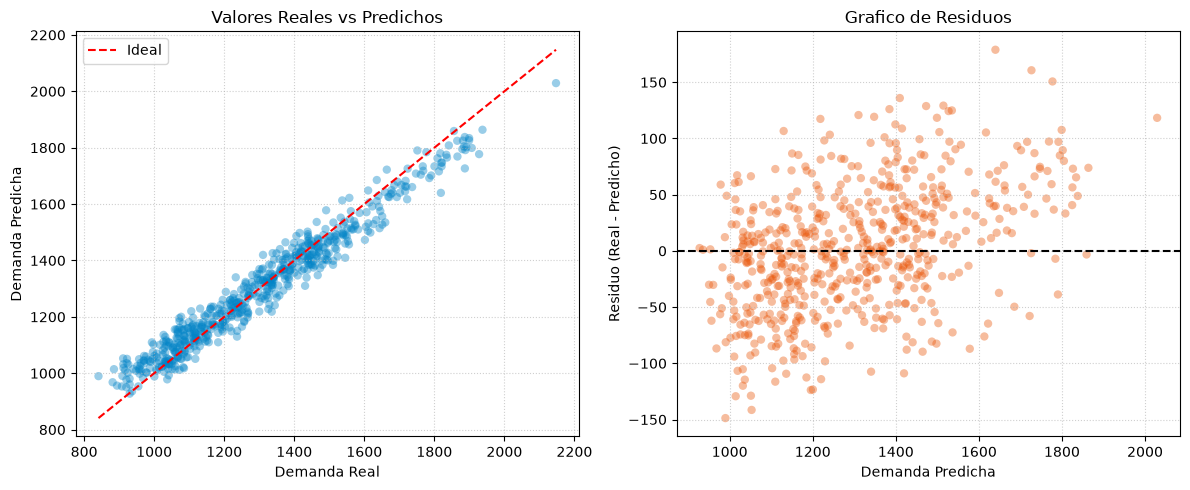

In [6]:
y_train_pred = pipeline.predict(X_train)
y_test_pred = pipeline.predict(X_test)
metrics = {
    **compute_metrics(y_train, y_train_pred, prefix="train_"),
    **compute_metrics(y_test, y_test_pred, prefix="test_"),
}
display(pd.DataFrame([
    {"partición": partition, **{m: metrics[f"{prefix}{m}"] for m in ["rmse", "mae", "r2"]}}
    for partition, prefix in [("entrenamiento", "train_"), ("prueba", "test_")]
]))
figure = create_evaluation_figure(y_test, y_test_pred)
display(figure)
plt.close(figure)


## 7. Registrar el experimento y el modelo en MLflow

El run almacena parámetros, métricas, un gráfico y predicciones de prueba.
**MLflow Models** empaqueta el pipeline con firma de entrada/salida y ejemplos.
Se incluye `src/` para que el transformador personalizado pueda importarse al
recuperar el modelo desde otro proceso. Las dependencias de inferencia se fijan
con las versiones del entorno utilizado.


In [7]:
from importlib.metadata import version
import inspect

sample_input = X_train.head(5)
signature = infer_signature(sample_input, pipeline.predict(sample_input))
# MLflow 2 usa artifact_path; MLflow 3 incorpora name.
model_location = (
    {"name": "demand_pipeline_model"}
    if "name" in inspect.signature(mlflow.sklearn.log_model).parameters
    else {"artifact_path": "demand_pipeline_model"}
)

with mlflow.start_run(run_name=f"notebook_ridge_alpha_{ALPHA}") as run:
    mlflow.set_tags({
        "project": "activity-05-databricks-mlflow",
        "source": "pipeline_mlflow.ipynb",
        "framework": "scikit-learn",
        "environment": "Databricks" if USE_DATABRICKS else "Local",
        "evaluation": "temporal_one_day_ahead",
    })
    mlflow.log_params({
        "model_type": "Ridge", "alpha": ALPHA, "seed": SEED,
        "n_rows": N_ROWS, "test_size": TEST_SIZE,
        "train_samples": len(X_train), "test_samples": len(X_test),
        "pipeline_steps": "DemandFeatures -> ColumnTransformer -> Ridge",
    })
    mlflow.log_metrics(metrics)
    mlflow.log_figure(figure, "evaluation/residuals.png")
    predictions = pd.DataFrame({
        "date": X_test["date"], "actual": y_test, "predicted": y_test_pred,
    })
    mlflow.log_text(predictions.to_csv(index=False), "evaluation/predictions.csv")
    model_info = mlflow.sklearn.log_model(
        sk_model=pipeline,
        **model_location,
        signature=signature,
        input_example=sample_input,
        serialization_format="cloudpickle",
        code_paths=[str(PROJECT_DIR / "src")],
        pip_requirements=[
            f"{package}=={version(package)}"
            for package in ["scikit-learn", "pandas", "numpy", "matplotlib", "cloudpickle"]
        ],
    )
    run_id = run.info.run_id
    model_uri = model_info.model_uri

print(f"Run ID: {run_id}")
print(f"Modelo: {model_uri}")


/home/donmathiuz/ml-engineering-portfolio/workshop/activity-05-databricks-mlflow/.venv/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(


2026/10/16 12:54:55 INFO mlflow.utils.uv_utils: Detected uv project: found uv.lock and pyproject.toml in /home/donmathiuz/ml-engineering-portfolio/workshop/activity-05-databricks-mlflow


2026/10/16 12:54:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/10/16 12:54:56 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Run ID: 9718b1d577c14057b5641a52cf648f85
Modelo: models:/m-d3b24919a7d04a369ce8563b4d79120e


## 8. Consultar los runs del experimento

La tabla permite revisar el historial de ejecuciones. Comparar resultados sobre
prueba es descriptivo: para ajustar hiperparámetros se debe reservar una partición
de validación temporal adicional.


In [8]:
runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    filter_string="attributes.status = 'FINISHED'",
    order_by=["start_time DESC"],
    max_results=20,
)
display(runs[[
    "run_id", "start_time", "params.alpha",
    "metrics.test_rmse", "metrics.test_mae", "metrics.test_r2",
]])


,run_id,start_time,params.alpha,metrics.test_rmse,metrics.test_mae,metrics.test_r2
0,9718b1d577c14057b5641a52cf648f85,2026-10-16 18:54:55.670000+00:00,1.0,55.418061,44.406978,0.947308


## 9. Cargar el modelo y comprobar la inferencia

Se recupera el modelo mediante su URI de MLflow. La comprobación confirma que el
pipeline serializado produce las mismas predicciones, incluyendo preprocesamiento.


In [9]:
loaded_pipeline = mlflow.sklearn.load_model(model_uri)
new_data = X_test.head(5).copy()
loaded_predictions = loaded_pipeline.predict(new_data)
np.testing.assert_allclose(loaded_predictions, pipeline.predict(new_data))
display(new_data.assign(predicted_demand=loaded_predictions))
print("Verificación correcta: las predicciones coinciden después de cargar el modelo.")


,date,average_temperature,rainfall,weekend,holiday,price_per_kg,promo,previous_days_demand,competitor_price_per_kg,marketing_intensity,predicted_demand
2400,2024-05-11,17.435299,15.963389,1,0,2.730358,0,1037.549000,0.594310,0.682232,1314.230440
2401,2024-05-12,18.244634,0.700782,1,0,0.748920,0,1334.762501,0.717380,0.546355,1458.881288
2402,2024-05-13,33.298609,1.138486,0,0,1.694683,1,1440.653923,0.554597,0.425048,1282.665365
2403,2024-05-14,27.047398,1.421311,0,0,2.742294,1,1346.884915,1.235038,0.503609,1231.748298
2404,2024-05-15,34.364760,5.047801,0,0,1.533048,0,1263.695715,0.633778,0.376929,1054.024348


Verificación correcta: las predicciones coinciden después de cargar el modelo.


## 10. Model Registry (opcional)

Activa `REGISTER_MODEL` para crear una versión del modelo. En local se utiliza el
registro de SQLite. En Databricks configura `REGISTRY_URI` (por ejemplo,
`databricks-uc`) y un nombre autorizado `catalog.schema.model`; el catálogo y
esquema deben existir. Registrar una versión no despliega un endpoint.


In [10]:
REGISTER_MODEL = False
REGISTERED_MODEL_NAME = "sklearn_demand_prediction_pipeline"
REGISTRY_URI = "databricks-uc" if USE_DATABRICKS else tracking_uri

if REGISTER_MODEL:
    if USE_DATABRICKS and REGISTRY_URI == "databricks-uc" and len(REGISTERED_MODEL_NAME.split(".")) != 3:
        raise ValueError("Usa un nombre catalog.schema.model para Unity Catalog.")
    mlflow.set_registry_uri(REGISTRY_URI)
    model_version = mlflow.register_model(model_uri, REGISTERED_MODEL_NAME)
    client = MlflowClient()
    print(f"Modelo registrado: {model_version.name} | Versión: {model_version.version}")
else:
    print("El modelo está guardado en MLflow Models. Registro de versión opcional desactivado.")


El modelo está guardado en MLflow Models. Registro de versión opcional desactivado.


## Revisar los resultados

Para el backend local predeterminado, ejecuta desde la carpeta de la actividad:
```bash
uv run mlflow ui --backend-store-uri sqlite:///mlflow.db --port 5000
```
Abre http://127.0.0.1:5000 y selecciona `activity-05-demand-notebook`.
Si elegiste otro backend, inicia la interfaz con esa misma URI.
En Databricks, abre **Experiments** en tu workspace y busca el nombre configurado.

Documentación oficial: [MLflow y scikit-learn](https://mlflow.org/docs/latest/api_reference/python_api/mlflow.sklearn.html).
